Linear Regression - Train R²: 0.008, Test R²: 0.013
Optimal Ridge α: 0.01 (Test R²: 0.013)
✅ Alpha-sweep plot successfully saved.


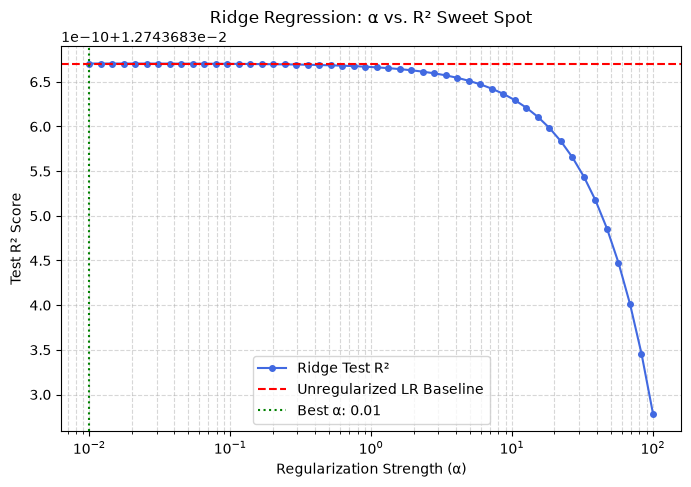

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score

# ==========================================
# 1. Load Dataset & Train-Test Split
# ==========================================
df = pd.read_csv('C:/Users/Pydis/Downloads/cp_data_demo.csv')

# Use Temperature to predict Heat_Capacity
X = df[['Temperature']]
y = df['Heat_Capacity']

# Ensure no NaN values exist
valid_mask = (~X['Temperature'].isna()) & (~y.isna())
X = X.loc[valid_mask]
y = y.loc[valid_mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 2. Unregularized Linear Regression Baseline
# ==========================================
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_train_r2 = r2_score(y_train, lr.predict(X_train))
lr_test_r2 = r2_score(y_test, lr.predict(X_test))
print(f"Linear Regression - Train R²: {lr_train_r2:.3f}, Test R²: {lr_test_r2:.3f}")

# ==========================================
# 3. Ridge Regression & Alpha Sweep (0.01 to 100)
# ==========================================
alphas = np.logspace(-2, 2, 50)
ridge_test_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    ridge_test_scores.append(r2_score(y_test, ridge.predict(X_test)))

# Find the best alpha
best_alpha = alphas[np.argmax(ridge_test_scores)]
best_score = max(ridge_test_scores)
print(f"Optimal Ridge α: {best_alpha:.2f} (Test R²: {best_score:.3f})")

# ==========================================
# 4. Plotting the Alpha Sweep
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(alphas, ridge_test_scores, marker='o', markersize=4, color='royalblue', label='Ridge Test R²')
plt.axhline(lr_test_r2, color='red', linestyle='--', label='Unregularized LR Baseline')
plt.axvline(best_alpha, color='green', linestyle=':', label=f'Best α: {best_alpha:.2f}')

plt.xscale('log')
plt.xlabel('Regularization Strength (α)')
plt.ylabel('Test R² Score')
plt.title('Ridge Regression: α vs. R² Sweet Spot')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

# Save the deliverable
plt.savefig('ridge_alpha_sweep.png', dpi=300, bbox_inches='tight')
print("✅ Alpha-sweep plot successfully saved.")
plt.show()